Generate H-functions for all three cases

assuming $\gamma$ is the het. parameter

# Defs

## Imports

In [1]:
import sys; sys.path.insert(0, '..') # add parent folder path where lib folder is
# user-defined
import couplingPI as cpi
import response as rp

from lib.util import get_phase

from sirv2 import rhs, coupling_social_gamma, coupling_physical_gamma, coupling_both_gamma, coupling_social_gamma, coupling_physical_gamma, coupling_both_gamma

from sirv_lib import load_system, periodic_zero_crossings, plot_crossings, get_pd, get_kw_sim, _redu


import lib

import sympy as sym
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os

from scipy.signal import find_peaks
import copy
from copy import deepcopy

# for labels
import string
upper_alphabet = string.ascii_uppercase 

from sympy.utilities.lambdify import implemented_function
imp_fn = implemented_function

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "Helvetica"
})

Matrix = sym.Matrix
CPI = cpi.couplingPI
rsp = rp.Response

## RHS coupled

In [2]:
def _full(t,y,systems,hds_dict,option='val'):
    """Full right-hand side. Note that the `coupling` functions contain heterogeneity too."""

    system1,system2 = systems
    pd1 = system1.pardict;pd2 = system2.pardict
    #hd1 = hds[0];hd2 = hds[1] # het. params
    y1 = y[:len(system1.var_names)];y2 = y[len(system1.var_names):]

    c1 = system1.coupling(y,pd1,hds_dict,option,0,version=a.version)
    c2 = system2.coupling(list(y2)+list(y1),pd2,hds_dict,option,1,version=a.version)

    out1 = (system1.rhs(t,y1,pd1,option,0) + c1)
    out2 = (system2.rhs(t,y2,pd2,option,1) + c2)
    return np.array(list(out1)+list(out2))

## RHS 3d avg

In [3]:
def _redu(t, y, a, eps, delta):
    """Averaged phase-isostable equations (eq. 20, Nicks et al. 2024), N=2,
    with heterogeneity delta in oscillator 0 (system1).

    phi = th1 - th0. H_k(chi) are stored with chi = th_j - th_i.
    Oscillator i pairs its own psi with H2/H5 and the other's psi with H3/H6.

    Heterogeneous terms (system1 only):
      h['lam'][6] : J_theta, coefficient of delta in the theta equation
      h['lam'][7] : J_psi,   coefficient of delta in the psi equation
    Both depend only on oscillator 0's own phase, so after averaging they are
    constants; they are evaluated once at 0.

    Assumes delta enters at order eps^0, i.e. load_h_sym key (0,0,0,1).
    If h['sym'][6] is zero, delta was multiplied by eps in the coupling
    function: change the key to (1,0,0,1) in load_h_sym and replace delta
    with eps*delta below.
    """
    phi = y

    h1 = a.system1.h['lam'][0]
    # h2 = a.system1.h['lam'][1]
    # h3 = a.system1.h['lam'][2]
    # h4 = a.system1.h['lam'][3]
    # h5 = a.system1.h['lam'][4]
    # h6 = a.system1.h['lam'][5]

    J_th = a.system1.h['lam'][6](0.)   # constant theta drift per unit delta
    # J_ps = a.system1.h['lam'][7](0.)   # constant psi forcing per unit delta

    k = a.system1.kappa_val

    # osc 0: own psi = ps1, argument th1 - th0 = phi, carries the heterogeneity
    dth0 = eps*h1(phi) + delta*J_th
    # osc 1: own psi = ps2, argument th0 - th1 = -phi
    dth1 = eps*h1(-phi)

    dphi = dth1 - dth0

    return dphi

## kwargs

### sim

In [4]:
# simulation keyword arguments
kw_sim = {'rtol':1e-7,'atol':1e-7,'method':'LSODA'}

### model parameters

see `get_pd` in `sirv_lib.py` 

# Response Functions

### get init

In [5]:
pardict = get_pd()
print(pardict)
init0 = [0.17603663,
  0.829848,
  0.99917684]
t = np.arange(0,1000,.01)
out = solve_ivp(rhs,[t[0],t[-1]],init0,t_eval=t,args=(pardict,),**kw_sim)

{'alpha': 0.01, 'beta': 0.5, 'gamma': 0.14285714285714285, 'eta': 0.14285714285714285, 'mu': 0.01, 'kappa': 300, 'rho': 0.01, 'psi': 0.5, 'zeta': 1, 'om': 1, 'om_fix': 1}


In [6]:
idxs = find_peaks(out.y[0])[0]
per = np.diff(t[idxs])[-1]

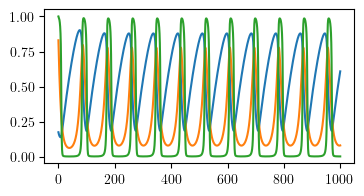

In [7]:
fig,axs = plt.subplots(figsize=(4,2))
axs.plot(out.t,out.y[0])
axs.plot(out.t,out.y[1])
axs.plot(out.t,out.y[2])
init = out.y.T[-1,:]
init = np.append(init,per)

# Coupling (social only)

In [8]:
# 387 approximate pitchfork 
kappas_social_gamma = np.round(np.arange(377,397,0.5),3)
as1_social_gamma = []
for kap in kappas_social_gamma:
    print(kap)
    try:
        system = load_system(kap,type1='social', par='gamma', load_data_only=True)
    except AttributeError:
        system = load_system(kap,type1='social', par='gamma', load_data_only=False)
    as1_social_gamma.append(system)

377.0
377.5
378.0
378.5
379.0
379.5
380.0
380.5
381.0
381.5
382.0
382.5
383.0
383.5
384.0
384.5
385.0
385.5
386.0
386.5
387.0
387.5
388.0
388.5
389.0
389.5
390.0
390.5
391.0
391.5
392.0
392.5
393.0
393.5
394.0
394.5
395.0
395.5
396.0
396.5


## plots (deltas)

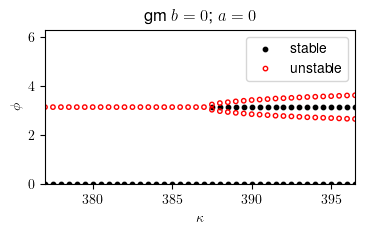

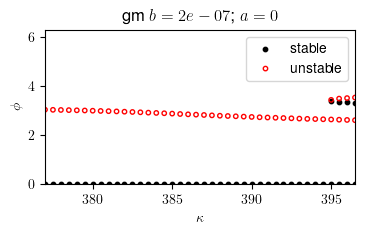

In [9]:
axs = plot_crossings(eps=.05, delta=0, kappas_in=kappas_social_gamma, systems=as1_social_gamma, type1='gm')
axs = plot_crossings(eps=.05, delta=2e-7, kappas_in=kappas_social_gamma, systems=as1_social_gamma, type1='gm')

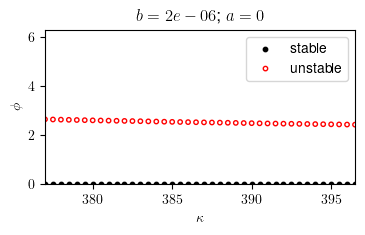

In [10]:
axs = plot_crossings(eps=.05, delta=2e-6, kappas_in=kappas_social_gamma, systems=as1_social_gamma)

## plots (aa)

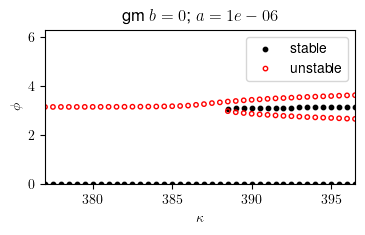

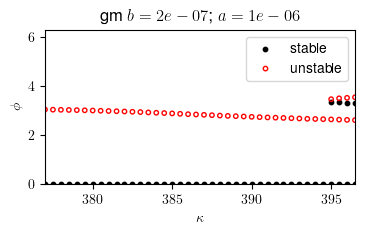

In [11]:
axs = plot_crossings(eps=.05, delta=0, aa=1e-6, kappas_in=kappas_social_gamma, systems=as1_social_gamma, type1='gm')
axs = plot_crossings(eps=.05, delta=2e-7, aa=1e-6, kappas_in=kappas_social_gamma, systems=as1_social_gamma, type1='gm')

# Coupling (physical only)

In [12]:
# 387 approximate pitchfork 
kappas_physical_gamma = np.round(np.arange(300,500,20),3)
as1_physical_gamma = []
for kap in kappas_physical_gamma:
    print(kap)
    try:
        system = load_system(kap, type1='physical', par='gamma', load_data_only=True)
    except AttributeError:
        system = load_system(kap,type1='physical', par='gamma', load_data_only=False)
    as1_physical_gamma.append(system)

300
320
340
360
380
400
420
440
460
480


## plots (deltas)

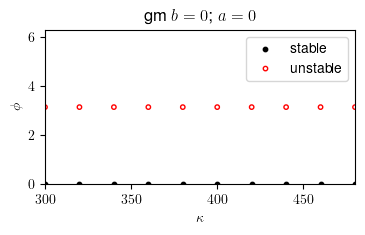

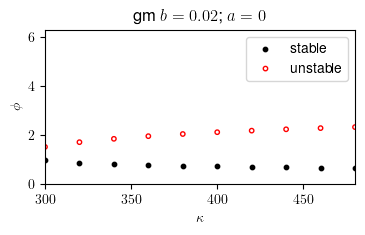

In [13]:
axs = plot_crossings(eps=.05, delta=0, kappas_in=kappas_physical_gamma, systems=as1_physical_gamma, type1='gm')
axs = plot_crossings(eps=.05, delta=0.02, kappas_in=kappas_physical_gamma, systems=as1_physical_gamma, type1='gm')

## plots (aa)

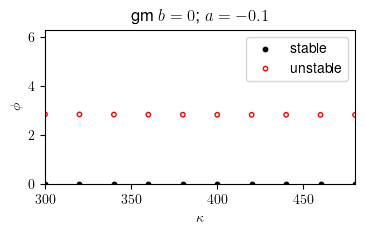

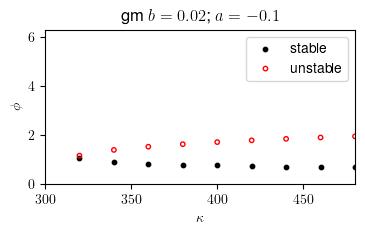

In [14]:
axs = plot_crossings(eps=.05, delta=0, aa=-.1, kappas_in=kappas_physical_gamma, systems=as1_physical_gamma, type1='gm')
axs = plot_crossings(eps=.05, delta=0.02, aa=-.1, kappas_in=kappas_physical_gamma, systems=as1_physical_gamma, type1='gm')

# Coupling (social + physical)

In [15]:
# 387 approximate pitchfork 
kappas_both_gamma = np.round(np.arange(300,302,.1),3)
as1_both_gamma = []
for kap in kappas_both_gamma:
    print(kap)
    try:
        system = load_system(kap, type1='both', par='gamma', load_data_only=True)
    except AttributeError:
        system = load_system(kap,type1='both', par='gamma', load_data_only=False)
    as1_both_gamma.append(system)

300.0
300.1
300.2
300.3
300.4
300.5
300.6
300.7
300.8
300.9
301.0
301.1
301.2
301.3
301.4
301.5
301.6
301.7
301.8
301.9


## plots

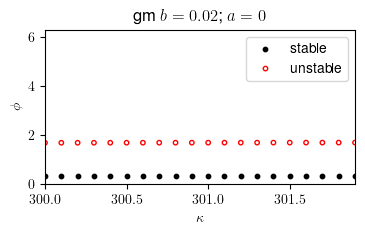

In [16]:
axs = plot_crossings(eps=.05, delta=0.02, kappas_in=kappas_both_gamma, systems=as1_both_gamma, type1='gm')

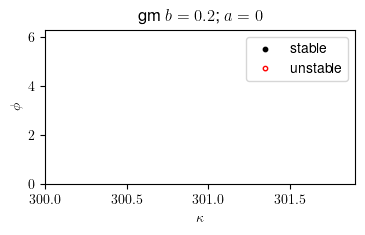

In [17]:
axs = plot_crossings(eps=.05, delta=0.2, kappas_in=kappas_both_gamma, systems=as1_both_gamma, type1='gm')